
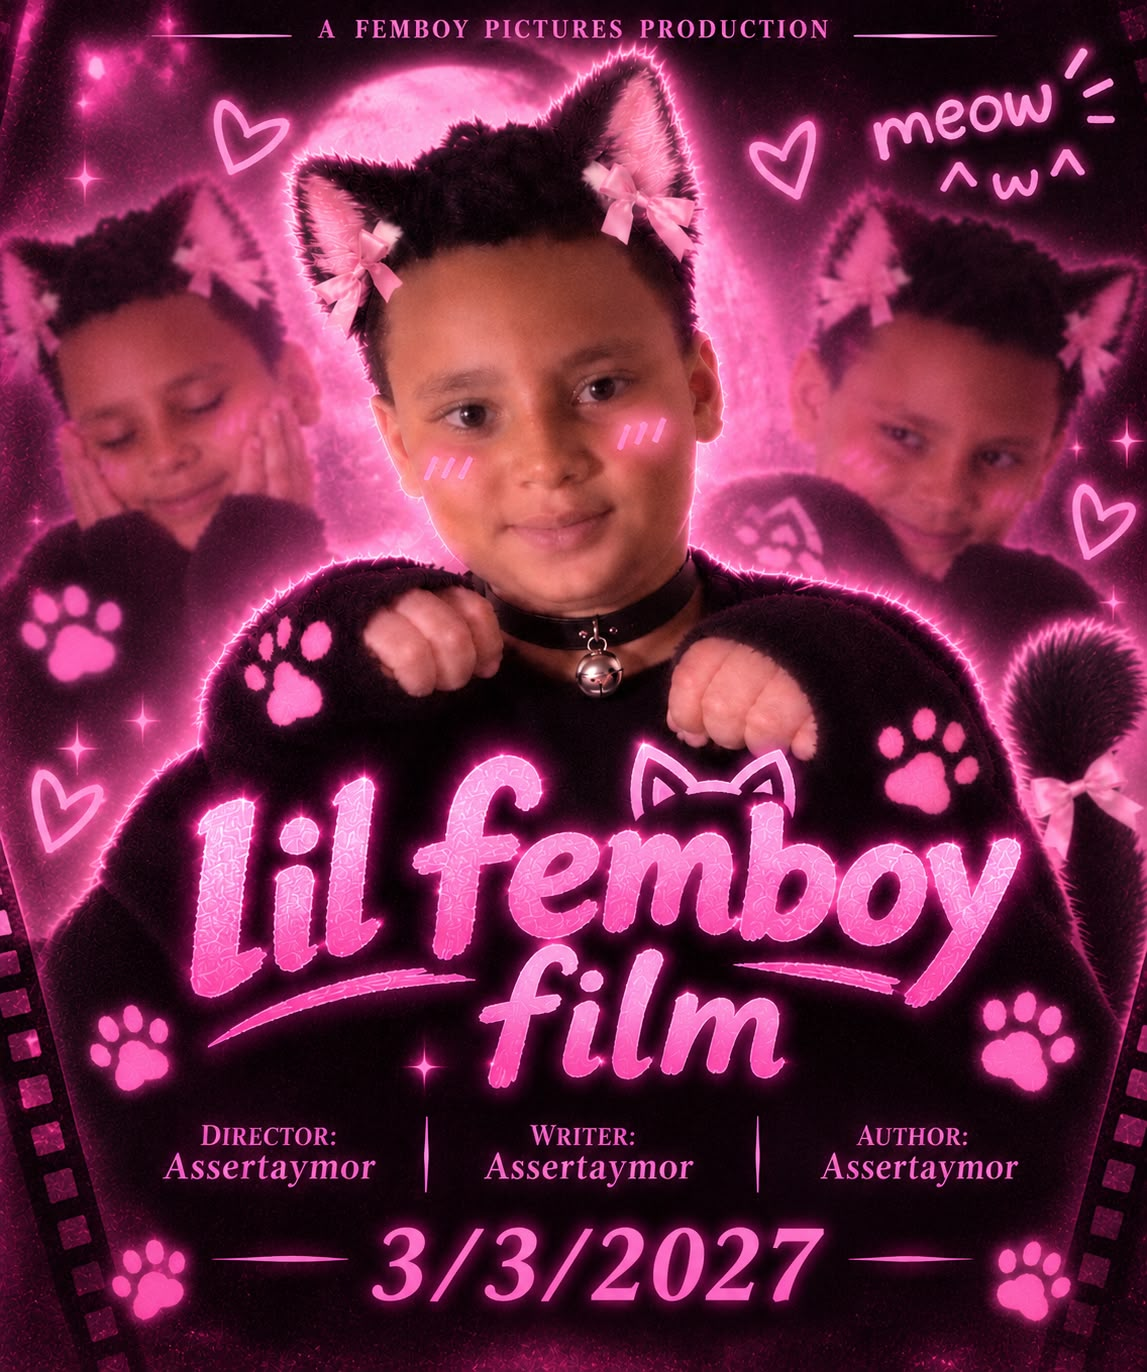

In [38]:
import base64
import IPython
import os

image_path = '/content/WhatsApp Image 2026-11-22 at 10.43.44 PM.jpeg'
img_base64 = ''
if os.path.exists(image_path):
    with open(image_path, 'rb') as img_file:
        img_base64 = base64.b64encode(img_file.read()).decode('utf-8')

html_content = f"""
<!DOCTYPE html>
<html lang='en'>
<head>
    <meta charset='UTF-8'>
    <meta name='viewport' content='width=device-width, initial-scale=1.0'>
    <title>Cinema Ticket Booking with Seat Selection</title>
    <style>
        body {{
            font-family: 'Segoe UI', Arial, sans-serif;
            background: #ffb6c1;
            color: #121212;
            display: flex;
            justify-content: center;
            align-items: center;
            min-height: 100vh;
            margin: 0;
            padding: 40px 20px;
        }}
        .booking-container {{
            background: #ffffff;
            border-radius: 12px;
            padding: 40px;
            box-shadow: 0 10px 30px rgba(0, 0, 0, 0.15);
            max-width: 550px;
            width: 100%;
            text-align: center;
        }}
        .poster {{
            width: 100%;
            max-height: 500px;
            object-fit: cover;
            border-radius: 8px;
            margin-top: 25px;
            margin-bottom: 70px;
            box-shadow: 0 4px 10px rgba(0, 0, 0, 0.1);
        }}
        h1 {{            margin: 0 0 15px 0;
            color: #ff69b4;
            font-size: 24px;
        }}
        .partner-link {{            display: inline-block;
            margin-bottom: 25px;
            color: #ff69b4;
            text-decoration: none;
            font-weight: bold;
            font-size: 14px;
        }}
        .partner-link:hover {{            text-decoration: underline;
        }}
        .movie-info {{            font-size: 14px;
            color: #555555;
            margin-bottom: 35px;
        }}
        .input-group {{
            margin-bottom: 25px;
            text-align: left;
            box-sizing: border-box;
        }}
        label {{            display: block;
            font-size: 14px;
            margin-bottom: 8px;
            color: #333333;
        }}
        input, select {{
            width: 100%;
            padding: 12px;
            border: 1px solid #ccc;
            border-radius: 6px;
            background: #fafafa;
            color: #333333;
            box-sizing: border-box;
        }}
        .price-summary {{            background: #f5f5f5;
            border-radius: 6px;
            padding: 15px;
            margin: 25px 0;
            font-size: 16px;
            color: #333333;
            display: flex;
            justify-content: space-between;
        }}
        .seat-selection-section {{            display: none;
            margin-top: 30px;
            text-align: center;
            border-top: 1px dashed #ccc;
            padding-top: 30px;
        }}
        .screen {{
            background: #e0e0e0;
            height: 10px;
            width: 80%;
            margin: 0 auto 25px auto;
            border-radius: 5px;
            box-shadow: 0 3px 8px rgba(0,0,0,0.1);
            font-size: 10px;
            color: #666;
            line-height: 10px;
        }}
        .seating-grid {{            display: grid;
            grid-template-columns: repeat(6, 1fr);
            gap: 10px;
            justify-content: center;
            margin: 20px auto;
            max-width: 320px;
        }}
        .seat {{
            background: #e0e0e0;
            border: 1px solid #bbb;
            height: 35px;
            border-radius: 6px;
            cursor: pointer;
            display: flex;
            align-items: center;
            justify-content: center;
            font-size: 11px;
            font-weight: bold;
            color: #333;
            transition: background 0.2s;
        }}
        .seat:hover {{
            background: #ffb6c1;
        }}
        .seat.selected {{            background: #ff69b4;
            color: #ffffff;
            border-color: #ff69b4;
        }}
        .btn-book, .btn-confirm-seats {{
            background: #ffffff;
            color: #ff69b4;
            border: 2px solid #ff69b4;
            padding: 12px 20px;
            font-size: 16px;
            font-weight: bold;
            border-radius: 6px;
            cursor: pointer;
            width: 100%;
            transition: 0.2s;
            box-shadow: 0 4px 6px rgba(0, 0, 0, 0.05);
            margin-top: 15px;
        }}
        .btn-book:hover, .btn-confirm-seats:hover {{            background: #ff69b4;
            color: #ffffff;
        }}
        .ticket-modal {{            display: none;
            background: #2ecc71;
            color: white;
            padding: 15px;
            border-radius: 6px;
            margin-top: 25px;
            font-weight: bold;
        }}
    </style>
</head>
<body>
    <div class='booking-container'>
        <img class='poster' src='data:image/jpeg;base64,{img_base64}' alt='Movie Poster' />
        <h1>Movie Ticket Portal</h1>
        <a href='http://tonytazkara.com' target='_blank' class='partner-link'>Visit tonytazkara.com</a>
        <p class='movie-info'>Experience the magic of cinema.</p>

        <div id='info-form'>
            <div class='input-group'>
                <label for='name'>Full Name</label>
                <input class='' type='text' id='name' placeholder='Your Name' value='Guest'>
            </div>

            <div class='input-group'>
                <label for='tickets'>Number of Tickets</label>
                <select id='tickets' onchange='updatePrice()'>
                    <option value='1'>1 Ticket</option>
                    <option value='2'>2 Tickets</option>
                    <option value='3'>3 Tickets</option>
                    <option value='4'>4 Tickets</option>
                    <option value='5'>5 Tickets</option>
                </select>
            </div>

            <div class='price-summary'>
                <span>Total Amount:</span>
                <span id='total-price'>$12.16</span>
            </div>

            <button class='btn-book' onclick='showSeatSelection()'>Proceed to Select Seats</button>
        </div>

        <!-- Seat Selection Step (Chairs) -->
        <div class='seat-selection-section' id='seat-selection-section'>
            <h3>Choose Your Chairs</h3>
            <div class='screen'>SCREEN</div>
            <div class='seating-grid' id='seating-grid'></div>
            <p id='seat-instruction' style='font-size:14px; color:#555;'>Please select exactly <span id='req-count'>1</span> seat(s).</p>
            <button class='btn-confirm-seats' onclick='confirmBooking()'>Complete Reservation</button>
        </div>

        <div class='ticket-modal' id='success-box'></div>
    </div>

    <script>
        const TICKET_PRICE = 12.16;
        let selectedSeats = [];

        function updatePrice() {{
            const qty = document.getElementById('tickets').value;
            const total = qty * TICKET_PRICE;
            document.getElementById('total-price').innerText = '$' + total.toFixed(2);
        }}

        function showSeatSelection() {{
            const qty = parseInt(document.getElementById('tickets').value);
            document.getElementById('req-count').innerText = qty;
            document.getElementById('seat-selection-section').style.display = 'block';
            document.getElementById('info-form').style.display = 'none';

            // Generate Seating Map (6 columns x 4 rows)
            const grid = document.getElementById('seating-grid');
            grid.innerHTML = '';
            selectedSeats = [];

            const rows = ['A', 'B', 'C', 'D'];
            for (let r = 0; r < rows.length; r++) {{
                for (let c = 1; c <= 6; c++) {{
                    const seatId = rows[r] + c;
                    const seat = document.createElement('div');
                    seat.className = 'seat';
                    seat.innerText = seatId;
                    seat.onclick = () => selectSeat(seat, seatId, qty);
                    grid.appendChild(seat);
                }}
            }}
        }}

        function selectSeat(seatElem, seatId, maxQty) {{
            if (seatElem.classList.contains('selected')) {{
                seatElem.classList.remove('selected');
                selectedSeats = selectedSeats.filter(s => s !== seatId);
            }} else {{
                if (selectedSeats.length < maxQty) {{
                    seatElem.classList.add('selected');
                    selectedSeats.push(seatId);
                }} else {{
                    alert('You have already selected ' + maxQty + ' chair(s). Deselect one to change.');
                }}
            }}
        }}

        function confirmBooking() {{
            const qty = parseInt(document.getElementById('tickets').value);
            if (selectedSeats.length !== qty) {{
                alert('Please select exactly ' + qty + ' chair(s) before completing reservation.');
                return;
            }}

            const name = document.getElementById('name').value || 'Guest';
            const total = qty * TICKET_PRICE;
            const box = document.getElementById('success-box');

            document.getElementById('seat-selection-section').style.display = 'none';
            box.style.display = 'block';
            box.innerHTML = '🎉 Order Confirmed!<br>' + qty + ' Ticket(s) booked for ' + name + '<br>Chairs: ' + selectedSeats.join(', ') + ' ($' + total.toFixed(2) + ')';
        }}
    </script>
</body>
</html>
"""
IPython.display.display(IPython.display.HTML(html_content))

